<center>
<h1><b>TP4 : Implémentation d'un système RAG</b></h1>
<h2><b>Retrieval-Augmented Generation appliqué à mon CV</b></h2>
</center>

# Présentation du TP

L'objectif est de mettre en place et d'évaluer une architecture **RAG** (*Retrieval-Augmented Generation*). Un LLM ne connaît pas le contenu d'un document privé. Le RAG lui donne accès à ce document : on recherche les passages utiles à la question, puis on les injecte dans le prompt avant la génération.

Étapes du TP (notebook `rag.ipynb` fourni) :

1. **Chargement et découpage** du document en blocs (*chunks*) ;
2. **Indexation et vectorisation** des chunks dans une base vectorielle (ChromaDB) ;
3. **Recherche** (*retrieval*) des chunks les plus proches de la question ;
4. **Génération et évaluation** : injection du contexte dans le prompt, puis notation de la réponse par un LLM juge.

Comme demandé dans la consigne, le document utilisé n'est pas `nc346.pdf` mais **mon propre CV** (`CV_fr_nophoto_full.pdf`), dont je connais le contenu : je peux donc vérifier moi-même si les réponses sont justes.

Les réponses rédigées se trouvent dans [`REPONSES.md`](REPONSES.md).

**Adaptations par rapport au notebook fourni** (détaillées dans `REPONSES.md`) :

- pas de clé OpenAI : le LLM du RAG est `openai/gpt-oss-20b` et le juge `openai/gpt-oss-120b`, tous deux servis gratuitement par **Groq** (`ChatGroq`) ;
- Groq ne propose pas de modèle d'embedding : les embeddings viennent de **Gemini** (`gemini-embedding-001`, API gratuite) ;
- quelques erreurs du code fourni sont corrigées (`search_Kwargs={'k',5}`, doublons dans la base Chroma, `print(display(...))`).

# 0. Préparation de l'environnement

Projet géré avec `uv` :

```
uv init
uv venv
Set-ExecutionPolicy -ExecutionPolicy RemoteSigned -Scope Process
.venv\Scripts\activate
uv add ipykernel langchain langchain-groq langchain-google-genai langchain-text-splitters langchain-community langchain-chroma chromadb tiktoken pypdf python-dotenv pandas matplotlib session-info
```

Les clés d'API sont lues depuis un fichier `.env` non versionné :

```
GROQ_API_KEY=...
GOOGLE_API_KEY=...
```

In [1]:
import re
import json
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
import session_info
import tiktoken
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from dotenv import load_dotenv
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import PyPDFLoader
from langchain_chroma import Chroma
from langchain_groq import ChatGroq
from langchain_google_genai import GoogleGenerativeAIEmbeddings

pd.set_option("display.max_colwidth", None)
plt.rcParams["figure.dpi"] = 110

In [2]:
session_info.show()

In [3]:
load_dotenv(".env", override=True)

True

## LLM

Le notebook fourni utilise `ChatOpenAI(model="gpt-4o-mini", temperature=0)`. Sans clé OpenAI, j'utilise `openai/gpt-oss-20b` via Groq (modèle open source, gratuit sur Groq). `temperature=0` rend les réponses quasi déterministes.

In [4]:
llm = ChatGroq(model="openai/gpt-oss-20b", temperature=0, max_retries=10)
llm.invoke("Réponds en un mot : quelle est la capitale du Maroc ?").content

'Rabat'

# 1. Chargement du PDF et découpage (*chunking*)

Le CV est placé dans le dossier `pdfs/`. Pour charger un dossier entier, on utiliserait `PyPDFDirectoryLoader(path="./pdfs")`.

In [5]:
pdf_file = "./pdfs/CV_fr_nophoto_full.pdf"
pdf_loader = PyPDFLoader(pdf_file)
pages = pdf_loader.load()
len(pages)

2

Le dépôt GitHub est public et les sorties du notebook affichent des extraits du document. Avant l'indexation, je retire donc les deux lignes de coordonnées personnelles (téléphone et e-mail) du texte extrait. C'est aussi une bonne pratique en RAG : ne pas indexer de données personnelles dont le système n'a pas besoin.

In [6]:
for page in pages:
    page.page_content = re.sub(r"^(Tel|Email):.*\n", "", page.page_content, flags=re.M)

print(pages[0].page_content[:400])

WAHIB
EL BESSALI
Étudiant en Master Sciences et Techniques (AI & Digital Computing)
GitHub: wahib-elbessali
LinkedIn: wahib-el-bessali
Étudiant en Master Sciences et Techniques (AI & Digital Computing), à l’intersection entre intelligence artiﬁcielle et ingénierie logicielle
: de l’entraînement distribué de modèles génératifs à l’architecture d’applications sécurisées en production. Une double sen


Découpage avec `RecursiveCharacterTextSplitter` et l'encodeur `tiktoken` `o200k_base` : chaque chunk fait au plus **300 tokens** avec un chevauchement (*overlap*) de **20 tokens**. Le chevauchement évite qu'une information coupée entre deux chunks soit perdue.

Le notebook fourni utilise `pdf_loader.load_and_split(text_splitter)`. Comme les pages ont déjà été chargées et nettoyées, j'appelle l'équivalent `text_splitter.split_documents(pages)`.

In [7]:
text_splitter = RecursiveCharacterTextSplitter.from_tiktoken_encoder(encoding_name="o200k_base", chunk_size=300, chunk_overlap=20)
chunks = text_splitter.split_documents(pages)
len(chunks)

10

In [8]:
encoder = tiktoken.get_encoding("o200k_base")
chunks_df = pd.DataFrame({
    "chunk": range(len(chunks)),
    "page": [c.metadata["page"] + 1 for c in chunks],
    "tokens": [len(encoder.encode(c.page_content)) for c in chunks],
    "début du chunk": [c.page_content[:80].replace("\n", " ") for c in chunks],
})
chunks_df

,chunk,page,tokens,début du chunk
0,0,1,287,WAHIB EL BESSALI Étudiant en Master Sciences et Techniques (AI & Digital Computi
1,1,1,201,"FST Béni Mellal | 2025 – Présent Spécialisation en Machine Learning, Deep Learni"
2,2,1,274,EXPÉRIENCE . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . .
3,3,1,289,"intelligent des colonnes, transfert sécurisé de ﬁchiers via SFTP , tableaux de b"
4,4,1,295,"PyTorch, Swin Transformer, Deep Learning | GitHub Reproduction et analyse critiq"
5,5,1,91,"hôpitaux simulés sur des rounds successifs d’agrégation pondérée, chacun appliqu"
6,6,2,293,"City Sensor : Cluster IoT et Visualisation Temps Réel Python, NumPy/SciPy, FastA"
7,7,2,255,implémenté sans dépendre d’un cœur d’émulation existant. ChalkTalk : Plateforme
8,8,2,293,"projets, suivi des tâches, messagerie interne. COMPÉTENCES . . . . . . . . . . ."
9,9,2,205,"Sécurité & Authentiﬁcation JWT , Firebase Authentication, Auth.js, bcrypt Design"


Un CV de deux pages donne seulement une dizaine de chunks (contre 161 pour la note de conjoncture de 52 pages du notebook fourni). Chaque chunk correspond à peu près à une section ou à un projet du CV.

# 2. Base vectorielle ChromaDB et embeddings

## 2.1 Modèle d'embedding

Le notebook fourni utilise `OpenAIEmbeddings(model="text-embedding-3-small")`. Groq ne fournit pas d'embeddings, j'utilise donc `gemini-embedding-001` de Google (gratuit). Chaque texte devient un vecteur de 3072 dimensions.

In [9]:
embedding_model = GoogleGenerativeAIEmbeddings(model="gemini-embedding-001")
vecteur = embedding_model.embed_query("Stage de fin d'études")
len(vecteur), vecteur[:5]

(3072, [0.009110754, 0.02497147, 0.0035059152, -0.06896502, 0.0095280325])

## 2.2 Vectorisation et stockage

Les chunks sont vectorisés puis stockés dans une base Chroma persistée dans le dossier `store/`.

Correction : dans le notebook fourni, chaque réexécution de `Chroma.from_documents(...)` avec le même `persist_directory` **ajoute à nouveau** tous les chunks à la collection, qui se remplit de doublons (le retriever renvoie alors plusieurs fois le même chunk). Je donne un identifiant fixe à chaque chunk (`ids=`), ce qui remplace les chunks existants au lieu de les dupliquer.

In [10]:
vectorstore = Chroma.from_documents(
    chunks,
    embedding_model,
    ids=[f"chunk_{i}" for i in range(len(chunks))],
    collection_name="cv_wahib",
    persist_directory="./store",
)
vectorstore._collection.count()

10

# 3. Trouver les chunks liés à la question (*Retriever*)

Correction : le notebook fourni écrit `search_Kwargs={'k',5}`. Il y a deux erreurs : la majuscule à `Kwargs` (le paramètre attendu est `search_kwargs`) et `{'k',5}` qui est un *set* Python et non un dictionnaire. Le paramètre est donc ignoré et le retriever garde sa valeur par défaut `k=4` : c'est pour cela que le notebook fourni affiche 4 chunks au lieu de 5. La bonne écriture est `search_kwargs={"k": 5}`.

In [11]:
retriever = vectorstore.as_retriever(search_type="similarity", search_kwargs={"k": 5})

Test avec la question : *« Où Wahib a-t-il effectué son stage de fin d'études ? »*

In [12]:
retrieved_chunks = retriever.invoke("Où Wahib a-t-il effectué son stage de fin d'études ?")
print("nombre de chunks :", len(retrieved_chunks))
for rang, doc in enumerate(retrieved_chunks, 1):
    print(f"\n----- chunk {rang} (page {doc.metadata['page'] + 1}) -----")
    print(doc.page_content[:300])

nombre de chunks : 5

----- chunk 1 (page 1) -----
WAHIB
EL BESSALI
Étudiant en Master Sciences et Techniques (AI & Digital Computing)
GitHub: wahib-elbessali
LinkedIn: wahib-el-bessali
Étudiant en Master Sciences et Techniques (AI & Digital Computing), à l’intersection entre intelligence artiﬁcielle et ingénierie logicielle
: de l’entraînement dist

----- chunk 2 (page 1) -----
EXPÉRIENCE . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . .
Stage de Fin d’Études (AFMOS MAROC)
Développement d’Application d

----- chunk 3 (page 1) -----
FST Béni Mellal | 2025 – Présent
Spécialisation en Machine Learning, Deep Learning et architectures de calcul haute performance, axée sur le traitement de
données massives et le déploiement de modèles prédictifs.
Licence en Sciences et Techniques (Génie Informatique)
FST Settat | 2024 –

Pour voir la proximité de chaque chunk, `similarity_search_with_score` renvoie aussi la distance entre le vecteur de la question et celui du chunk (plus elle est petite, plus le chunk est proche).

In [13]:
resultats = vectorstore.similarity_search_with_score("Où Wahib a-t-il effectué son stage de fin d'études ?", k=5)
pd.DataFrame({
    "distance": [round(score, 4) for _, score in resultats],
    "page": [doc.metadata["page"] + 1 for doc, _ in resultats],
    "début du chunk": [doc.page_content[:80].replace("\n", " ") for doc, _ in resultats],
})

,distance,page,début du chunk
0,0.5475,1,WAHIB EL BESSALI Étudiant en Master Sciences et Techniques (AI & Digital Computi
1,0.6308,1,EXPÉRIENCE . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . .
2,0.6608,1,"FST Béni Mellal | 2025 – Présent Spécialisation en Machine Learning, Deep Learni"
3,0.7162,2,"Sécurité & Authentiﬁcation JWT , Firebase Authentication, Auth.js, bcrypt Design"
4,0.7608,2,"projets, suivi des tâches, messagerie interne. COMPÉTENCES . . . . . . . . . . ."


Le premier chunk renvoyé est l'en-tête du CV, et non la section *Expérience* qui arrive en deuxième position. La question contient le prénom « Wahib », qui n'apparaît que dans l'en-tête : la similarité vectorielle tient compte de tous les mots, pas seulement de l'intention de la question. Comme `k=5`, le chunk *Expérience* fait quand même partie du contexte et le LLM peut répondre. C'est une raison de ne pas prendre un `k` trop petit.

# 4. *Prompt Design*

## 4.1 Prompt template

Le prompt reprend celui du notebook fourni. La phrase qui décrit le contexte est adaptée au document (mon CV). Le contexte est délimité par `<context>`, la question par `<question>`. Pour limiter les hallucinations, le modèle doit répondre `Je ne sais pas!` si la réponse n'est pas dans le contexte.

In [14]:
prompt_template = """
Answer the following question based only on provided context. The context is about the CV of
Wahib El Bessali, a Master's student in AI & Digital Computing (education, experience, projects, skills, languages).
The context is delimited by <context> tag
The user question is delimited by <question> tag
If the answer is not found in the context, answer: Je ne sais pas!
<context>
{context}
</context>
<question>
{question}
</question>
"""

## 4.2 Récupération des documents pertinents (*retrieving*)

On récupère les chunks, on garde uniquement leur texte (`page_content`) et on les concatène avec le séparateur `". "` pour former le contexte. Cette étape est mise dans une fonction `retrieve_context` pour être réutilisée par le RAG et par le juge.

In [15]:
def retrieve_context(query):
    relevant_document_chunks = retriever.invoke(query)
    context_list = [d.page_content for d in relevant_document_chunks]
    return ". ".join(context_list)

In [16]:
user_input = "Où Wahib a-t-il effectué son stage de fin d'études ?"
context_for_query = retrieve_context(user_input)
print(len(context_for_query), "caractères")
print(context_for_query[:600])

4107 caractères
WAHIB
EL BESSALI
Étudiant en Master Sciences et Techniques (AI & Digital Computing)
GitHub: wahib-elbessali
LinkedIn: wahib-el-bessali
Étudiant en Master Sciences et Techniques (AI & Digital Computing), à l’intersection entre intelligence artiﬁcielle et ingénierie logicielle
: de l’entraînement distribué de modèles génératifs à l’architecture d’applications sécurisées en production. Une double sensibilité
pour la recherche (comprendre et reproduire les architectures qui font avancer le domaine) et pour l’implémentation bas niveau, quand
la compréhension complète d’un système passe par sa const


## 4.3 Le prompt

On injecte le contexte et la question dans le template avec `format`. Le prompt final contient :

1. les instructions (*Answer the following question ... Je ne sais pas!*) ;
2. le contexte entre `<context>` et `</context>` ;
3. la question entre `<question>` et `</question>`.

In [17]:
prompt = prompt_template.format(context=context_for_query, question=user_input)
print(prompt)


Answer the following question based only on provided context. The context is about the CV of
Wahib El Bessali, a Master's student in AI & Digital Computing (education, experience, projects, skills, languages).
The context is delimited by <context> tag
The user question is delimited by <question> tag
If the answer is not found in the context, answer: Je ne sais pas!
<context>
WAHIB
EL BESSALI
Étudiant en Master Sciences et Techniques (AI & Digital Computing)
GitHub: wahib-elbessali
LinkedIn: wahib-el-bessali
Étudiant en Master Sciences et Techniques (AI & Digital Computing), à l’intersection entre intelligence artiﬁcielle et ingénierie logicielle
: de l’entraînement distribué de modèles génératifs à l’architecture d’applications sécurisées en production. Une double sensibilité
pour la recherche (comprendre et reproduire les architectures qui font avancer le domaine) et pour l’implémentation bas niveau, quand
la compréhension complète d’un système passe par sa construction sans dépendre

# 5. Réponse du LLM

On envoie le prompt au LLM. Le notebook fourni écrit `print(display(Markdown(...)))`, ce qui affiche un `None` en trop après la réponse (`display` ne renvoie rien) : j'appelle simplement `display(...)`.

In [18]:
resp = llm.invoke(prompt)
display(Markdown(resp.content))

Il a effectué son stage de fin d’études chez **AFMOS MAROC**.

La réponse est correcte : le stage a eu lieu chez AFMOS MAROC (avril à juin 2025).

# 6. Regroupement dans une application RAG

La fonction `RAG(query, llm, prompt_template)` enchaîne les trois étapes :

1. **Retriever** : recherche des chunks pertinents pour la question ;
2. **Concaténation** : les textes des chunks forment le contexte ;
3. **Génération** : contexte et question sont injectés dans le template, puis envoyés au LLM.

In [19]:
def RAG(query, llm=llm, prompt_template=prompt_template):
    context_for_query = retrieve_context(query)
    prompt = prompt_template.format(context=context_for_query, question=query)
    resp = llm.invoke(prompt)
    return resp.content

## 6.1 Appel du RAG

Question dont la réponse est dans le CV :

In [20]:
display(Markdown(RAG("Quelles technologies ont été utilisées pour l'application desktop développée chez AFMOS MAROC ?")))

Les technologies principales utilisées pour l’application desktop développée chez AFMOS MAROC sont :

- **React** (interface utilisateur)  
- **Rust** (logique métier et backend)  
- **Tauri** (framework de création d’applications desktop)  

En complément, l’application s’appuie sur :

- **MySQL** via **SQLx** (base de données)  
- **AES‑256‑GCM** pour le chiffrement des sessions  
- **bcrypt** pour le hachage des mots‑de‑passe.

Question hors sujet (celle du notebook fourni, qui porte sur la note de conjoncture) :

In [21]:
display(Markdown(RAG("Quelle est la capitalisation boursière du Maroc pour 2025 ?")))

Je ne sais pas!

Le modèle répond `Je ne sais pas!` : la consigne anti-hallucination du prompt fonctionne, alors que le LLM aurait pu inventer un chiffre.

## 6.2 Série de questions

Je pose dix questions : sept dont la réponse est dans le CV et trois dont la réponse n'y est pas (dont le numéro de téléphone, retiré avant l'indexation).

In [22]:
questions = [
    ("Où Wahib a-t-il effectué son stage de fin d'études et sur quoi portait-il ?", "dans le CV"),
    ("Quelles technologies ont été utilisées pour l'application desktop développée chez AFMOS MAROC ?", "dans le CV"),
    ("Quel score FID obtient le projet Conditional StyleGAN2-ADA par rapport à la baseline ?", "dans le CV"),
    ("Quelle précision et quelle vitesse atteint la meilleure variante de ST-LaneNet ?", "dans le CV"),
    ("Quelles bases de données Wahib maîtrise-t-il ?", "dans le CV"),
    ("Quel est le parcours universitaire de Wahib ?", "dans le CV"),
    ("Quelles langues parle Wahib ?", "dans le CV"),
    ("Quel est le numéro de téléphone de Wahib ?", "hors CV"),
    ("Quelle est la capitalisation boursière du Maroc pour 2025 ?", "hors CV"),
    ("Quel salaire Wahib demande-t-il pour son prochain poste ?", "hors CV"),
]

In [23]:
reponses = [RAG(q) for q, _ in questions]
rag_df = pd.DataFrame({
    "question": [q for q, _ in questions],
    "type": [t for _, t in questions],
    "réponse du RAG": reponses,
})
rag_df.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"})

,question,type,réponse du RAG
0,Où Wahib a-t-il effectué son stage de fin d'études et sur quoi portait-il ?,dans le CV,"Wahib a effectué son stage de fin d’études chez **AFMOS MAROC**. Il a travaillé sur le **développement d’une application desktop sécurisée de digitalisation de la gestion RH** de l’entreprise, en utilisant React, Rust, Tauri, etc."
1,Quelles technologies ont été utilisées pour l'application desktop développée chez AFMOS MAROC ?,dans le CV,"Les technologies principales utilisées pour l’application desktop développée chez AFMOS MAROC sont : - **React** (interface utilisateur) - **Rust** (logique métier et sécurité) - **Tauri** (framework de création d’applications desktop légères) En complément, l’application s’appuie sur : - **MySQL** via **SQLx** (base de données) - **AES‑256‑GCM** pour le chiffrement des sessions - **bcrypt** pour le hachage des mots‑de‑passe."
2,Quel score FID obtient le projet Conditional StyleGAN2-ADA par rapport à la baseline ?,dans le CV,"Le projet Conditional StyleGAN2‑ADA obtient un score FID de **30,15**, contre **70,08** pour la baseline."
3,Quelle précision et quelle vitesse atteint la meilleure variante de ST-LaneNet ?,dans le CV,"La meilleure variante de ST‑LaneNet atteint **91,86 % de précision** et fonctionne à **162,9 FPS**."
4,Quelles bases de données Wahib maîtrise-t-il ?,dans le CV,"Wahib maîtrise les bases de données suivantes : **MySQL, PostgreSQL, MongoDB, Supabase, SQLx** et **Cypher**."
5,Quel est le parcours universitaire de Wahib ?,dans le CV,"Wahib El Bessali a suivi un parcours universitaire structuré autour des sciences et techniques : - **DEUST en MIP** (FST Settat) : 2021 – 2024, tronc commun axé sur les mathématiques, la physique et l’informatique. - **Licence en Sciences et Techniques – Génie Informatique** (FST Settat) : 2024 – 2025, obtenue avec Mention Très Bien. - **Master en Sciences et Techniques – AI & Digital Computing** (FST Béni Mellal) : 2025 – Présent, spécialisé en Machine Learning, Deep Learning et architectures de calcul haute performance."
6,Quelles langues parle Wahib ?,dans le CV,"Wahib parle : l’arabe, l’anglais et le français."
7,Quel est le numéro de téléphone de Wahib ?,hors CV,Je ne sais pas!
8,Quelle est la capitalisation boursière du Maroc pour 2025 ?,hors CV,Je ne sais pas!
9,Quel salaire Wahib demande-t-il pour son prochain poste ?,hors CV,Je ne sais pas!


Les sept réponses attendues sont retrouvées dans le CV, et les trois questions hors CV reçoivent `Je ne sais pas!`.

# 7. Évaluation de la réponse du LLM (LLM juge)

## 7.1 Architecture

![Architecture RAG et juge](./rag_juge.gif)

Le RAG récupère le contexte dans la base vectorielle et le LLM1 génère la réponse. Un second LLM, le **juge**, reçoit la question, le contexte et la réponse, puis attribue un score de 1 à 5.

Le juge doit être plus puissant que le modèle du RAG. Le notebook fourni utilise `gpt-4o` pour juger `gpt-4o-mini` ; ici `openai/gpt-oss-120b` juge `openai/gpt-oss-20b`.

In [24]:
groundness_checker = ChatGroq(model="openai/gpt-oss-120b", temperature=0, max_retries=10)

In [25]:
user_message_template = """
###Question
{question}
###Context
{context}
###Answer
{answer}
"""

## 7.2 *Groundedness* (fidélité au contexte)

Le prompt du juge reprend celui du notebook fourni. J'ajoute seulement une dernière ligne qui impose le format `Score : X` à la fin, pour pouvoir extraire la note automatiquement et faire un tableau récapitulatif.

In [26]:
groundness_rater_system_message = """
Vous êtes chargé d'évaluer des réponses générées par une IA à des questions posées par des utilisateurs.
On vous présentera une question, le contexte utilisé par le système d'IA pour générer la réponse, ainsi qu'une réponse générée par l'IA à la question.
Dans l'entrée, la question commencera par ###Question, le contexte commencera par ###Context, et la réponse générée par L'IA commencera par ###Answer.
Critères d'évaluation :
La tâche consiste à juger dans quelle mesure la réponse respecte la métrique.

1- La métrique n'est pas respectée du tout
2- La métrique n'est respectée que dans une mesure limitée
3- La métrique est respectée dans une bonne mesure
4- La métrique est respectée en grande partie
5- La métrique est entièrement respectée

Métrique :

La réponse doit être dérivée uniquement des informations présentées dans le contexte.

Instructions:

Écrivez d'abord les étapes nécessaires pour évaluer la réponse selon la métrique.
Donnez une explication étape par étape indiquant si la réponse respecte la métrique, en considérant la question et le contexte comme entrées.
Évaluez ensuite dans quelle mesure la métrique est respectée.
Utilisez les informations précédentes pour noter la réponse selon les critères d'évaluation et attribuer un score.
Terminez obligatoirement par une dernière ligne de la forme : Score : X
"""

Correction : dans le notebook fourni, `evaluate` appelle le retriever pour construire le contexte, puis `RAG(question)` qui refait sa propre recherche. Le contexte vu par le juge et celui utilisé pour la réponse sont donc calculés deux fois. Ici le contexte est calculé une seule fois et sert aux deux, ce qui garantit que le juge évalue la réponse par rapport au contexte réellement utilisé. La fonction renvoie aussi la réponse, pour pouvoir l'afficher.

In [27]:
def evaluate(system_message, user_message_template, question, model=groundness_checker):
    context = retrieve_context(question)
    answer = llm.invoke(prompt_template.format(context=context, question=question)).content
    prompt = f"""
     {system_message}\n
     USER:
     {user_message_template.format(question=question, context=context, answer=answer)}
     """
    juge_response = model.invoke(prompt)
    return answer, juge_response.content


def extraire_score(texte):
    scores = re.findall(r"Score[\s*]*:[\s*]*([1-5])", texte)
    return int(scores[-1]) if scores else None

In [28]:
user_input = "Quel score FID obtient le projet Conditional StyleGAN2-ADA par rapport à la baseline ?"
answer, juge = evaluate(groundness_rater_system_message, user_message_template, user_input)
display(Markdown("**Réponse du RAG :** " + answer))
display(Markdown(juge))

**Réponse du RAG :** Le projet Conditional StyleGAN2‑ADA obtient un score FID de **30,15**, contre **70,08** pour la baseline.

**Étapes d’évaluation selon la métrique**

1. **Identifier la question**  
   - La question demande le score FID du projet *Conditional StyleGAN2‑ADA* et le compare à la baseline.

2. **Extraire les informations pertinentes du contexte**  
   - Rechercher dans le texte tout passage contenant « Conditional StyleGAN2‑ADA » et « FID ».  
   - Le contexte indique : « Surpasse la baseline en qualité ( FID 30,15 contre 70,08 ) ».

3. **Comparer la réponse générée avec les informations extraites**  
   - Vérifier que la réponse ne cite que les valeurs de FID présentes dans le contexte et qu’elle ne rajoute aucune donnée non‑mentionnée.

4. **Déterminer si la réponse est strictement dérivée du contexte**  
   - La réponse doit être une reformulation exacte ou une paraphrase fidèle des valeurs trouvées, sans inférence supplémentaire.

5. **Attribuer une note selon le degré de conformité**  
   - 1 : aucune conformité.  
   - 2 : conformité très limitée.  
   - 3 : bonne conformité mais avec quelques écarts.  
   - 4 : grande conformité, presque parfaite.  
   - 5 : conformité totale, réponse entièrement tirée du contexte.

**Application de l’évaluation**

- Le contexte fournit clairement les deux scores : FID = 30,15 pour le projet et FID = 70,08 pour la baseline.  
- La réponse de l’IA indique exactement ces deux valeurs : « Le projet Conditional StyleGAN2‑ADA obtient un score FID de **30,15**, contre **70,08** pour la baseline. »  
- Aucun élément supplémentaire n’est ajouté et aucune information n’est omise.  
- La réponse est donc une reformulation fidèle et exclusive du texte fourni.

**Évaluation**

La réponse respecte intégralement la métrique : elle est entièrement dérivée des informations présentées dans le contexte.

**Score : 5**

### Échelle de notation pour la fidélité au contexte

| Score | Signification | Description |
| :--- | :--- | :--- |
| **5 / 5** | **Excellent** | La réponse utilise **uniquement** les informations du contexte. Aucune hallucination, aucune extrapolation. |
| **4 / 5** | **Bon** | La réponse est correcte et s'appuie sur le contexte, mais la formulation pourrait être plus précise. |
| **3 / 5** | **Moyen** | La réponse est partiellement vraie, mais omet un détail important du contexte ou manque de clarté. |
| **2 / 5** | **Médiocre** | La réponse contient des extrapolations ou des informations non vérifiables avec le contexte. |
| **1 / 5** | **Mauvais (hallucination)** | La réponse est hors sujet, fausse, ou invente des données absentes du contexte. |

## 7.3 *Relevance* (pertinence de la réponse)

La fidélité seule ne suffit pas : une réponse `Je ne sais pas!` est parfaitement fidèle au contexte, mais elle ne répond pas à la question. J'ajoute donc une deuxième métrique, la **pertinence**, avec le même format de prompt : la réponse traite-t-elle bien la question posée, en s'appuyant sur le contexte ?

In [29]:
relevance_rater_system_message = groundness_rater_system_message.replace(
    "La réponse doit être dérivée uniquement des informations présentées dans le contexte.",
    "La réponse doit répondre de manière pertinente, complète et précise à la question posée, en exploitant les informations utiles du contexte.",
)

## 7.4 Évaluation de toutes les questions

Chaque question de la section 6.2 est notée par le juge sur les deux métriques.

In [30]:
resultats = []
for question, type_question in questions:
    answer, juge_g = evaluate(groundness_rater_system_message, user_message_template, question)
    _, juge_r = evaluate(relevance_rater_system_message, user_message_template, question)
    resultats.append({
        "question": question,
        "type": type_question,
        "réponse": answer,
        "groundedness": extraire_score(juge_g),
        "relevance": extraire_score(juge_r),
        "juge_groundedness": juge_g,
        "juge_relevance": juge_r,
    })

eval_df = pd.DataFrame(resultats)
eval_df[["question", "type", "réponse", "groundedness", "relevance"]].style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"})

,question,type,réponse,groundedness,relevance
0,Où Wahib a-t-il effectué son stage de fin d'études et sur quoi portait-il ?,dans le CV,"Il a effectué son stage de fin d’études chez **AFMOS MAROC**. Le projet consistait à développer une **application desktop sécurisée (React, Rust, Tauri)** pour digitaliser la gestion des ressources humaines de l’entreprise, en remplaçant les outils Excel et les documents papier.",5,5
1,Quelles technologies ont été utilisées pour l'application desktop développée chez AFMOS MAROC ?,dans le CV,"Les technologies principales utilisées pour l’application desktop développée chez AFMOS MAROC sont : - **React** (interface utilisateur) - **Rust** (logique métier et sécurité) - **Tauri** (framework de création d’applications desktop légères) En complément, l’application s’appuie sur : - **MySQL** via **SQLx** (base de données) - **AES‑256‑GCM** pour le chiffrement des sessions - **bcrypt** pour le hachage des mots‑de‑passe.",5,4
2,Quel score FID obtient le projet Conditional StyleGAN2-ADA par rapport à la baseline ?,dans le CV,"Le projet Conditional StyleGAN2‑ADA obtient un score FID de **30,15**, contre **70,08** pour la baseline.",5,5
3,Quelle précision et quelle vitesse atteint la meilleure variante de ST-LaneNet ?,dans le CV,"La meilleure variante de ST‑LaneNet atteint **91,86 % de précision** et fonctionne à **162,9 FPS**.",5,5
4,Quelles bases de données Wahib maîtrise-t-il ?,dans le CV,"Wahib maîtrise les bases de données suivantes : **MySQL, PostgreSQL, MongoDB, Supabase, SQLx** et **Cypher**.",5,5
5,Quel est le parcours universitaire de Wahib ?,dans le CV,"Wahib El Bessali a suivi un parcours universitaire structuré autour des sciences et techniques : - **DEUST en MIP** (FST Settat) : 2021 – 2024, tronc commun en sciences et techniques, axé sur les mathématiques, la physique et l’informatique. - **Licence en Sciences et Techniques – Génie Informatique** (FST Settat) : 2024 – 2025, mention Très Bien. - **Master en Sciences et Techniques (AI & Digital Computing)** (FST Béni Mellal) : 2025 – présent, spécialisation en Machine Learning, Deep Learning et architectures de calcul haute performance.",5,5
6,Quelles langues parle Wahib ?,dans le CV,"Arabe, anglais et français.",5,5
7,Quel est le numéro de téléphone de Wahib ?,hors CV,Je ne sais pas!,5,3
8,Quelle est la capitalisation boursière du Maroc pour 2025 ?,hors CV,Je ne sais pas!,1,1
9,Quel salaire Wahib demande-t-il pour son prochain poste ?,hors CV,Je ne sais pas!,5,1


In [31]:
eval_df.groupby("type")[["groundedness", "relevance"]].mean().round(2)

,groundedness,relevance
type,,
dans le CV,5.00,4.86
hors CV,3.67,1.67


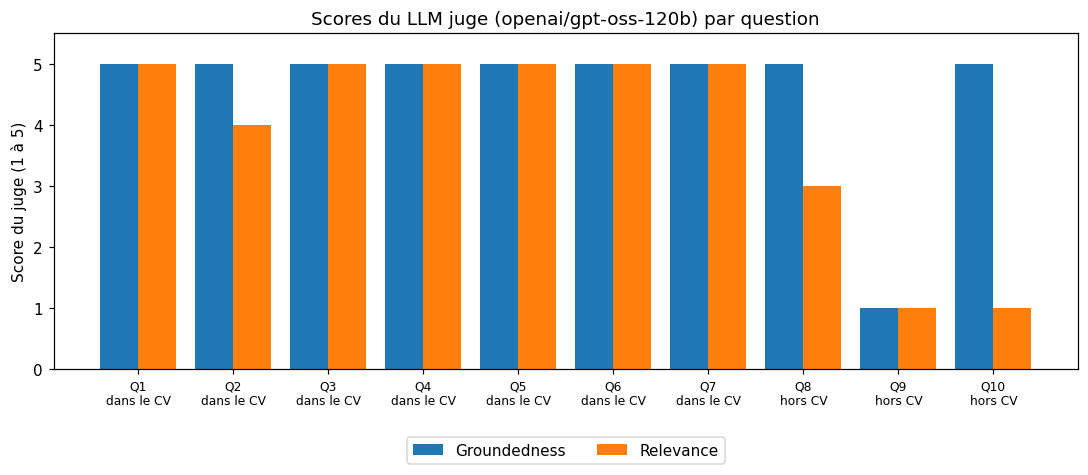

In [32]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x = range(len(eval_df))
ax.bar([i - 0.2 for i in x], eval_df["groundedness"], width=0.4, label="Groundedness")
ax.bar([i + 0.2 for i in x], eval_df["relevance"], width=0.4, label="Relevance")
ax.set_xticks(list(x))
ax.set_xticklabels([f"Q{i + 1}\n{t}" for i, t in enumerate(eval_df["type"])], fontsize=8)
ax.set_ylim(0, 5.5)
ax.set_ylabel("Score du juge (1 à 5)")
ax.set_title("Scores du LLM juge (openai/gpt-oss-120b) par question")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
plt.tight_layout()
plt.savefig("figures/01_scores_juge.png", bbox_inches="tight")
plt.show()

Exemple de raisonnement du juge pour une question hors CV (pertinence) :

In [33]:
display(Markdown(eval_df.loc[eval_df["type"] == "hors CV", "juge_relevance"].iloc[0]))

**Étapes d’évaluation selon la métrique**

1. **Identifier la question** – déterminer exactement ce qui est demandé.  
2. **Analyser le contexte** – extraire toutes les informations utiles qui pourraient répondre à la question.  
3. **Comparer le contenu de la réponse** avec les informations disponibles :  
   - La réponse est‑elle pertinente ? (traite‑t‑elle le sujet de la question)  
   - La réponse est‑elle complète ? (fournit‑elle tout ce qui peut être déduit du contexte)  
   - La réponse est‑elle précise ? (évite‑t‑elle les approximations ou les affirmations non fondées)  
4. **Vérifier l’exploitation du contexte** – la réponse doit s’appuyer sur les données du contexte ou, le cas échéant, expliquer l’absence d’information.  
5. **Attribuer un score** de 1 à 5 selon le degré de conformité avec la métrique.

---

**Application de ces étapes à la réponse fournie**

1. **Question** : « Quel est le numéro de téléphone de Wahib ? »  
2. **Contexte** : Le texte décrit le profil académique et professionnel de Wahib El Bessali, ses compétences, ses projets, ses réseaux sociaux (GitHub, LinkedIn) mais ne mentionne **aucun numéro de téléphone**.  
3. **Pertinence** : La réponse « Je ne sais pas ! » répond directement à la question en indiquant l’absence de connaissance. Elle est donc pertinente.  
4. **Complétude** : La réponse indique simplement l’incapacité à fournir le numéro, mais ne précise pas que le contexte ne le contient pas. Une réponse plus complète aurait ajouté une courte justification (« Le contexte fourni ne comporte pas de numéro de téléphone »).  
5. **Précision** : L’affirmation « Je ne sais pas » est exacte ; il n’y a pas d’information contradictoire dans le contexte.  
6. **Exploitation du contexte** : La réponse ne cite pas explicitement le fait que le contexte ne fournit pas le numéro, mais elle reflète correctement l’absence d’information.  

**Conclusion**  
La réponse est pertinente et précise, mais elle manque légèrement de complétude en ne mentionnant pas explicitement que le contexte ne contient pas le numéro demandé. Elle respecte donc la métrique dans une bonne mesure, sans être parfaite.

**Score attribué** : 3  

Score : 3

In [34]:
eval_df.to_json("data/evaluations.json", orient="records", force_ascii=False, indent=2)

## 7.5 Amélioration du prompt du juge

Le prompt de fidélité ne dit pas comment traiter une réponse `Je ne sais pas!`. Le juge peut alors hésiter : refuser de répondre n'invente rien (fidèle), mais la phrase « Je ne sais pas » n'est pas non plus « dérivée du contexte ». Le tableau de la section 7.4 le montre : le juge donne **1/5** à la réponse `Je ne sais pas!` sur la capitalisation boursière, avec le raisonnement « la réponse n'est pas dérivée du contexte », alors qu'il donne 5/5 à la même réponse pour les deux autres questions hors CV. Sur trois exécutions de ce notebook, cette réponse a reçu successivement 1, 5 puis 1 : malgré `temperature=0`, le juge n'est pas stable sur ce cas ambigu.

J'ajoute une précision au prompt pour lever l'ambiguïté et je réévalue les trois questions hors CV.

In [35]:
groundness_rater_system_message_v2 = groundness_rater_system_message.replace(
    "La réponse doit être dérivée uniquement des informations présentées dans le contexte.",
    "La réponse doit être dérivée uniquement des informations présentées dans le contexte. "
    "Si le contexte ne contient pas l'information demandée et que la réponse l'indique (par exemple « Je ne sais pas! ») sans rien inventer, la métrique est entièrement respectée.",
)

hors_cv = [q for q, t in questions if t == "hors CV"]
v2 = [extraire_score(evaluate(groundness_rater_system_message_v2, user_message_template, q)[1]) for q in hors_cv]
pd.DataFrame({
    "question": hors_cv,
    "groundedness (prompt initial)": eval_df.loc[eval_df["type"] == "hors CV", "groundedness"].tolist(),
    "groundedness (prompt v2)": v2,
})

,question,groundedness (prompt initial),groundedness (prompt v2)
0,Quel est le numéro de téléphone de Wahib ?,5,5
1,Quelle est la capitalisation boursière du Maroc pour 2025 ?,1,5
2,Quel salaire Wahib demande-t-il pour son prochain poste ?,5,5


# Conclusion

- Le pipeline RAG (chargement, découpage, embeddings, Chroma, retriever, prompt, LLM) répond correctement aux sept questions sur mon CV, alors que le LLM seul ne connaît pas ce document. J'ai vérifié chaque réponse avec le CV.
- La consigne `Je ne sais pas!` empêche le modèle d'inventer une réponse quand l'information n'est pas dans le contexte, y compris pour le numéro de téléphone retiré avant l'indexation.
- Le juge ne détecte aucune hallucination dans les réponses tirées du CV. Sur les réponses `Je ne sais pas!`, son jugement peut varier d'une exécution à l'autre quand le prompt ne précise pas ce cas (section 7.5).
- La métrique de pertinence complète la fidélité : elle distingue une vraie réponse d'un `Je ne sais pas!`, qui est fidèle mais ne répond pas.

L'analyse détaillée et les réponses sont dans [`REPONSES.md`](REPONSES.md).